In [1]:
import osgeo
import rasterio
import rioxarray
import xarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
#import tifffile

Open data and read it as array

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [3]:
path_LC_Hansen2 = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000.tif'

In [3]:
path_GLC_E0N10 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N10_Annual.tif'

In [5]:
path_GLC_E0N15 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E0N15_Annual.tif'

In [13]:
path_GLC_E25N70 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E20-E25/GLC_FCS30D_20002022_E25N70_Annual.tif'

In [7]:
path_GLC_W55S5 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_W55-W60/GLC_FCS30D_20002022_W55S5_Annual.tif'

In [4]:
LCHansen2000 = rasterio.open(path_LC_Hansen)

In [9]:
LCHansen20002 = rasterio.open(path_LC_Hansen2)

In [11]:
LCHansen2000

<open DatasetReader name='C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif' mode='r'>

Read GLC data as xarray

In [8]:
GLC_FCS302000E0N10 = rioxarray.open_rasterio(path_GLC_E0N10)

In [11]:
GLC_FCS302000E0N15 = rioxarray.open_rasterio(path_GLC_E0N15)

In [14]:
GLC_FCS302000E25N70 = rioxarray.open_rasterio(path_GLC_E25N70)

In [13]:
GLC_FCS302000W55S5 = rioxarray.open_rasterio(path_GLC_W55S5)

Show metadata

with tifffile.TiffFile(path_LC_Hansen2) as tif:
    for page in tif.pages:
        print(page.tags)

with tifffile.TiffFile(path_LC_Hansen2) as tif:
    for page in tif.pages:
        for tag in page.tags.values():
            print(tag.name, tag.value)

with tifffile.TiffFile(path_LC_Hansen2) as tif:
    print(tif.pages[0].tags)

Select year 2000

In [9]:
GLC_FCS302000E0N10

<xarray.DataArray (band: 23, y: 18554, x: 18554)> Size: 8GB
[7917771068 values with dtype=uint8]
Coordinates:
  * band         (band) int64 184B 1 2 3 4 5 6 7 8 9 ... 16 17 18 19 20 21 22 23
  * y            (y) float64 148kB 10.0 10.0 9.999 9.999 ... 5.001 5.0 5.0 5.0
  * x            (x) float64 148kB 0.0001347 0.0004042 0.0006737 ... 5.0 5.0 5.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [12]:
GLC_FCS302000E0N10band1 = GLC_FCS302000E0N10.sel(band=1)

In [15]:
GLC_FCS302000E0N15band1 = GLC_FCS302000E0N15.sel(band=1)

In [15]:
GLC_FCS302000E25N70band1 = GLC_FCS302000E25N70.sel(band=1)

In [17]:
GLC_FCS302000W55S5band1 = GLC_FCS302000W55S5.sel(band=1)

In [8]:
GLC_FCS302000E0N10band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
[344250916 values with dtype=uint8]
Coordinates:
  * y            (y) float64 148kB 10.0 10.0 9.999 9.999 ... 5.001 5.0 5.0 5.0
  * x            (x) float64 148kB 0.0001347 0.0004042 0.0006737 ... 5.0 5.0 5.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Show bounds

left → min X (longitude or easting)
right → max X
bottom → min Y (latitude or northing)
top → max Y

In [20]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


In [21]:
bounds = GLC_FCS302000E0N10band1.rio.bounds()
print(bounds)

(0.0, 4.99979746553392, 5.00020253446608, 10.0)


In [22]:
bounds = GLC_FCS302000E0N15band1.rio.bounds()
print(bounds)

(0.0, 9.99979746553392, 5.00020253446608, 15.0)


In [23]:
bounds = GLC_FCS302000E25N70band1.rio.bounds()
print(bounds)

(25.0, 64.99979746553392, 30.000202534466077, 70.0)


In [24]:
bounds = GLC_FCS302000W55S5band1.rio.bounds()
print(bounds)

(-55.0, -10.00020253446608, -49.999797465533916, -5.0)


## LH forest classification

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, broadleaved, deciduous, closed to open (>15%) 60
Tree cover, broadleaved, deciduous, closed (>40%) 61
Tree cover, broadleaved, deciduous, open (15 – 40%) 62
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72
Tree cover needle leaved deciduous, closed to open (>15%) 80
Tree cover needle leaved deciduous, closed (>40%) 81
Tree cover needle leaved deciduous, open (15 – 40%) 82
Tree cover, mixed leaf type (broadleaved and needle leaved) 90

## GLC forest classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92

In [16]:
LCHansen2000array = LCHansen2000.read(1)
LCHansen2000array.shape
print(LCHansen2000array[:-50, :-50])

[[210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 [210. 210. 210. ... 210. 210. 210.]
 ...
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]
 [220. 220. 220. ... 220. 220. 220.]]


In [8]:
type(LCHansen2000array)

numpy.ndarray

In [16]:
len(LCHansen2000array)

3600

Check coordinate system

In [11]:
LCHansen2000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [12]:
GLC_FCS302000E0N10band1.rio.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

Select areas with forest

In [17]:
maskLCHansen2000 = (LCHansen2000array >= 50) & (LCHansen2000array <= 90)
# Apply mask (set others to NaN for visualization)
LCHansen2000filtered = np.where(maskLCHansen2000, LCHansen2000array, np.nan)

In [19]:
maskLCHansen2000

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(3600, 7200))

Plot forest areas C Hansen

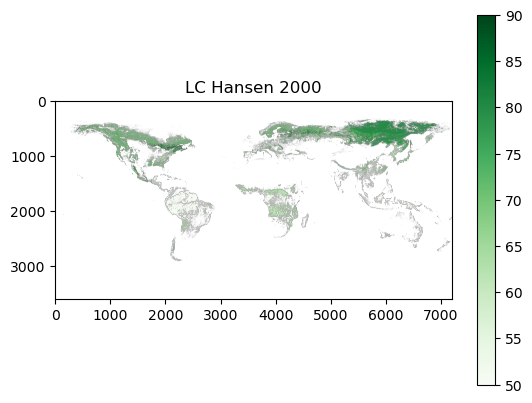

In [14]:
pyplot.imshow(LCHansen2000filtered, cmap='Greens')
pyplot.title("LC Hansen 2000")
pyplot.colorbar()

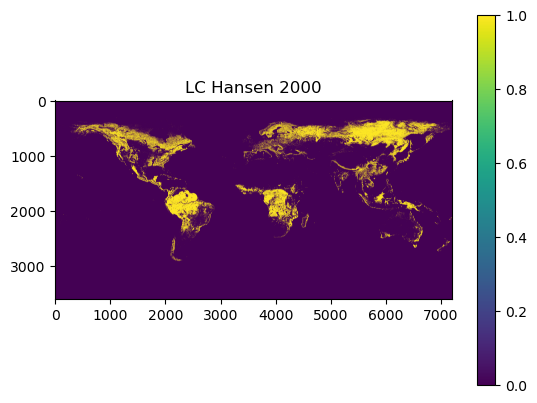

In [23]:
pyplot.imshow(mask)
pyplot.title("LC Hansen 2000")
pyplot.colorbar()

Plot GLC_FCS302000E0N10band1

In [12]:
type(GLC_FCS302000E0N10band1)

xarray.core.dataarray.DataArray

Select areas with forest

In [24]:
maskGLC_FCS302000E0N10band1 = (GLC_FCS302000E0N10band1 >= 51) & (GLC_FCS302000E0N10band1 <= 92)
# Apply mask (set others to NaN for visualization)

In [20]:
maskGLC_FCS302000E25N70band1 = (GLC_FCS302000E25N70band1 >= 51) & (GLC_FCS302000E25N70band1 <= 92)
# Apply mask (set others to NaN for visualization)

In [27]:
GLC_FCS302000E0N10band1filtered = GLC_FCS302000E0N10band1.where(maskGLC_FCS302000E0N10band1, drop=True)

In [21]:
GLC_FCS302000E25N70band1filtered = GLC_FCS302000E25N70band1.where(maskGLC_FCS302000E25N70band1, drop=True)

In [25]:
maskGLC_FCS302000E0N10band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False,  True, False],
       [False, False, False, ...,  True,  True, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 10.0 10.0 9.999 9.999 ... 5.001 5.0 5.0 5.0
  * x            (x) float64 148kB 0.0001347 0.0004042 0.0006737 ... 5.0 5.0 5.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [28]:
GLC_FCS302000E0N10band1filtered

<xarray.DataArray (y: 16343, x: 18554)> Size: 1GB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, 71., nan],
       [nan, nan, nan, ..., 91., 71., nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(16343, 18554), dtype=float32)
Coordinates:
  * y            (y) float64 131kB 10.0 10.0 9.999 9.999 ... 5.002 5.002 5.001
  * x            (x) float64 148kB 0.0001347 0.0004042 0.0006737 ... 5.0 5.0 5.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

# Plotting

## Plot areas with forest GLC

NameError: name 'plt' is not defined

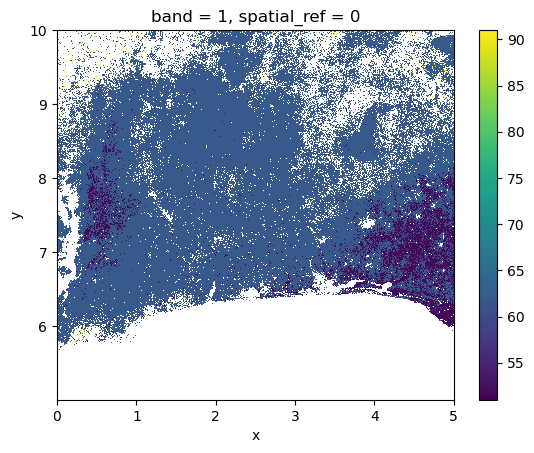

In [29]:
GLC_FCS302000E0N10band1filtered.plot()
plt.show()

In [ ]:
GLC_FCS302000E25N70band1filtered.plot()

## Plot LC Hansen E0 N10

In [24]:
minx, miny, maxx, maxy = 0.0, 4.999797465533919, 5.000202534466081, 10.0

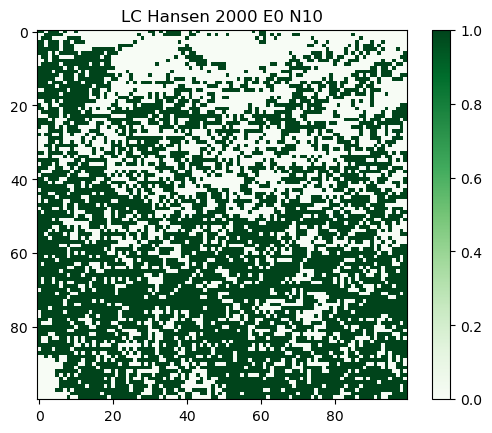

In [73]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLCHansen2000E0N10 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLCHansen2000E0N10 = np.where(maskLCHansen2000E0N10, subset, np.nan)

pyplot.imshow(maskLCHansen2000E0N10, cmap='Greens')
pyplot.title("LC Hansen 2000 E0 N10")
pyplot.colorbar()

# Resample GLC E25 N70

In [40]:
minx, miny, maxx, maxy = 25.0, 64.99979746553392, 30.000202534466077, 70.0

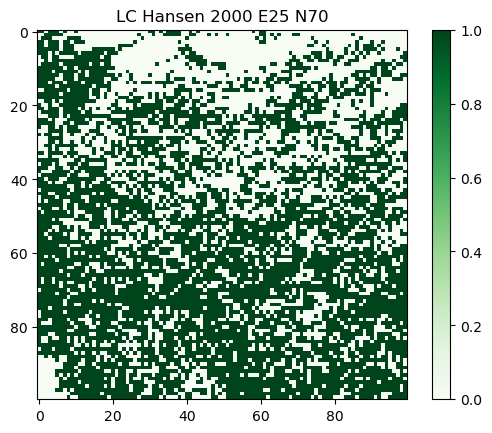

In [42]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLC_HansenE25N70 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLC_HansenE25N70 = np.where(maskLC_HansenE25N70, subset, np.nan)

pyplot.imshow(maskLC_HansenE25N70, cmap='Greens')
pyplot.title("LC Hansen 2000 E25 N70")
pyplot.colorbar()

In [52]:
maskLC_HansenE25N70

array([[ True,  True, False, ..., False, False, False],
       [False, False,  True, ..., False, False, False],
       [False,  True,  True, ..., False, False, False],
       ...,
       [False, False, False, ...,  True, False,  True],
       [False, False, False, ...,  True,  True,  True],
       [False, False, False, ...,  True,  True,  True]], shape=(100, 100))

Resample FCS data

In [53]:
LCHansen20003 = rioxarray.open_rasterio(path_LC_Hansen)

In [67]:
croppedLCHansen2000E25N70 = LCHansen20003.rio.clip_box(
    minx=25.0,
    miny=64.99979746553392,
    maxx=30.000202534466077,
    maxy=70.0
)

In [68]:
croppedLCHansen2000E25N70

<xarray.DataArray (band: 1, y: 101, x: 101)> Size: 41kB
[10201 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [27]:
maskGLC_FCS302000E25N70band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[ True, False, False, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       ...,
       [False, False, False, ...,  True,  True,  True],
       [False, False, False, ...,  True,  True,  True],
       [False, False, False, ...,  True,  True,  True]],
      shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 70.0 70.0 70.0 70.0 ... 65.0 65.0 65.0 65.0
  * x            (x) float64 148kB 25.0 25.0 25.0 25.0 ... 30.0 30.0 30.0 30.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [32]:
maskGLC_FCS302000E25N70band1int = maskGLC_FCS302000E25N70band1.astype(int)

Resample with interp

In [71]:
maskGLC_FCS302000E25N70band1int_interp = maskGLC_FCS302000E25N70band1int.interp(x = croppedLCHansen2000E25N70['x'], y = croppedLCHansen2000E25N70['y'], method='nearest')

In [72]:
maskGLC_FCS302000E25N70band1int_interp

<xarray.DataArray (y: 101, x: 101)> Size: 82kB
array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))
Coordinates:
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

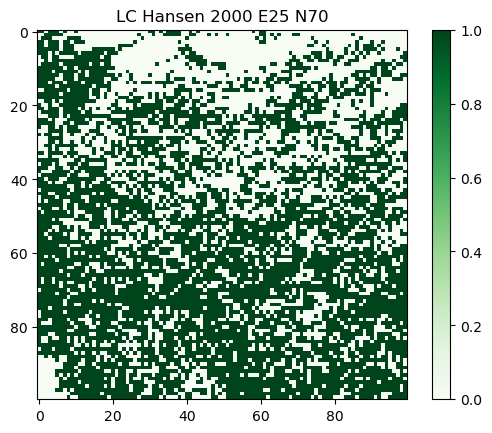

In [76]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLC_HansenE25N70 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLC_HansenE25N70 = np.where(maskLC_HansenE25N70, subset, np.nan)

pyplot.imshow(maskLC_HansenE25N70, cmap='Greens')
pyplot.title("LC Hansen 2000 E25 N70")
pyplot.colorbar()

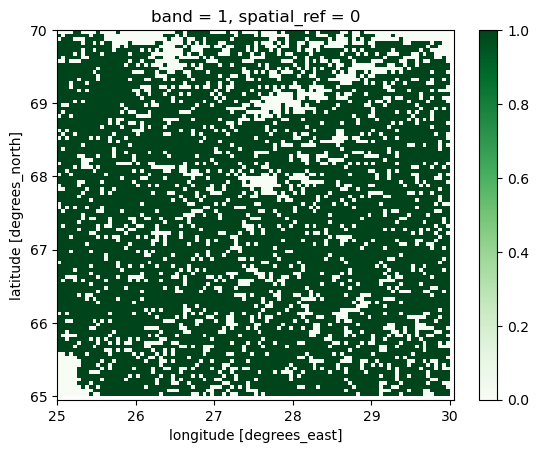

In [78]:
maskGLC_FCS302000E25N70band1int_interp.plot(cmap="Greens")


# Compare the LC maps

In [81]:
maskLC_HansenE25N70.astype(int)

array([[1, 1, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [0, 1, 1, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], shape=(100, 100))

In [80]:
maskGLC_FCS302000E25N70band1int_interp

<xarray.DataArray (y: 101, x: 101)> Size: 82kB
array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))
Coordinates:
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [83]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interp.values

In [84]:
maskGLC_FCS302000E25N70band1int_interparr

array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))

In [86]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interparr[:-1, :-1]

# Count differences

In [91]:
differences = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr != maskLC_HansenE25N70))

In [93]:
differences

2913

In [99]:
same = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == maskLC_HansenE25N70))

In [100]:
same

7087

In [103]:
all = differences+same

In [104]:
all

10000

In [105]:
differences/all

0.2913